# CS156 Session 9 — Metrics and Cross-Validation

In this session, I explore how to evaluate machine-learning models on data they have not seen before. Training a model is only one part of the process; I also need to check whether the model generalizes beyond its training examples.

The main ideas I explore are:

- train, validation, and test splits;
- random and stratified splitting;
- accuracy and its limitations;
- ROC curves and ROC-AUC;
- classification thresholds;
- hyperparameter tuning;
- avoiding data leakage.

The overall workflow is:

**Train → Validate and choose → Test once**

The final test set should remain untouched until I have finished making decisions about the model.

# Basic Questions for Class: Train/Test Split

Before comparing models, I first create the binary classification dataset used in this session.

The dataset contains two concentric circles. Each observation has two input features:

- **Feature 0:** horizontal coordinate;
- **Feature 1:** vertical coordinate.

The target has two classes:

- **0:** outside circle;
- **1:** inside circle.

This is useful because the classes do not have a simple linear boundary. Therefore, I can later compare a linear classifier with a model that can learn a nonlinear boundary.

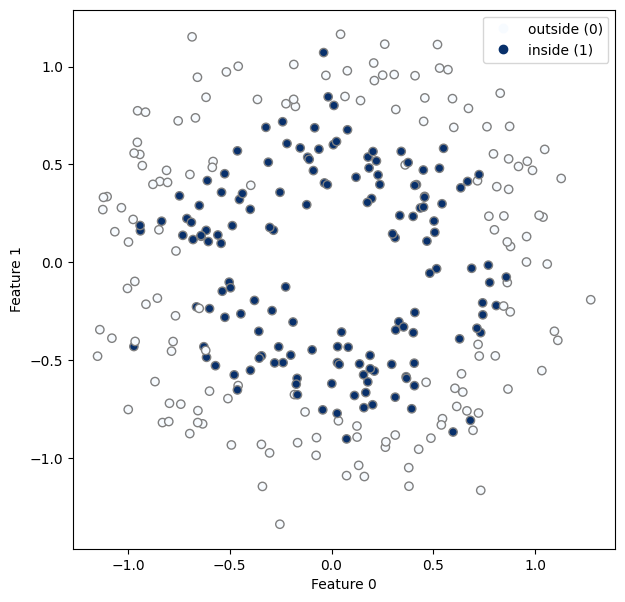

In [1]:
# Importing tools for generating data and splitting datasets
from sklearn import datasets, model_selection

# Importing plotting and numerical tools
import matplotlib.pyplot as plt
import numpy as np

# Setting the total number of observations
NUM_DATAPOINTS = 300

# Generating two noisy concentric circles for binary classification
x_data, y_data = datasets.make_circles(
    n_samples=NUM_DATAPOINTS,
    noise=0.15,
    factor=0.6)

# Creating a square figure
fig, ax = plt.subplots(figsize=(7, 7))

# Plotting Feature 0 against Feature 1 and coloring points by class
scatter = ax.scatter(
    x_data[:, 0],
    x_data[:, 1],
    c=y_data,
    edgecolors="grey",
    cmap="Blues",
    vmin=0,
    vmax=1)

# Labeling the axes
ax.set_xlabel("Feature 0")
ax.set_ylabel("Feature 1")

# Explaining the two classes
ax.legend(
    handles=scatter.legend_elements()[0],
    labels=["outside (0)", "inside (1)"])

plt.show()

## Interpretation

The plot shows that the two classes form concentric circles. This means a straight decision boundary would not naturally separate the classes.

At this point, I have only generated and visualized the data; I have not trained a machine-learning model yet.

# Q1: Split the X and y Values Into Train and Test Sets With an 80/20 Ratio

I now separate the data into training and test sets.

The training data will be used to fit the models, while the test data will remain unseen during training and will later be used to evaluate generalization.

I use an **80/20 split**, so:

- 80% of observations go into training;
- 20% go into testing.

Because this is a classification problem, I also use stratification so that the proportions of classes 0 and 1 remain approximately equal in both sets.

In [2]:
# Splitting the dataset into 80% training data and 20% test data
x_train, x_test, y_train, y_test = model_selection.train_test_split(
    x_data,
    y_data,
    test_size=0.2,
    random_state=42,
    shuffle=True,
    stratify=y_data)

# Checking the resulting dataset sizes
print("Training features:", x_train.shape)
print("Test features:", x_test.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)

Training features: (240, 2)
Test features: (60, 2)
Training labels: (240,)
Test labels: (60,)


## Interpretation

With 300 observations, this split should give approximately:

- 240 training observations;
- 60 test observations.

`shuffle=True` randomly mixes the observations before splitting, while `stratify=y_data` keeps the two class proportions approximately balanced.

`random_state=42` makes the split reproducible, meaning I will obtain the same train-test split when I rerun this code.

# Q2: What Kind of Split Are We Doing Above?

The split is a **random, stratified split**.

It is random because the observations are shuffled before 80% are assigned to training and 20% to testing. It is stratified because `stratify=y_data` keeps approximately the same proportions of classes 0 and 1 in both sets.

If I instead put every observation with Feature 0 > 0 into training and every observation with Feature 0 < 0 into testing, I would create a **non-random, feature-based split**.

That would likely make the task harder because the model would learn only from one side of the feature space and then be evaluated on a region it had never seen. The training and test sets would also come from different distributions.

Therefore, this alternative split would answer a different question. Instead of testing ordinary generalization to new observations from the same population, it would test whether the model can extrapolate from one region of the feature space to another.

# Core Questions: Comparing Logistic Regression and SVM

I now train two classifiers:

1. **Logistic Regression**
2. **Support Vector Machine (SVM)** with an RBF kernel

Logistic Regression creates a linear decision boundary. However, the classes in this dataset are concentric circles, so there is no straight line that can cleanly separate them.

The SVM can learn a nonlinear decision boundary, so I expect it to perform better on this particular dataset.

In [3]:
# Importing classification models and evaluation tools
from sklearn import linear_model, metrics, svm

# Creating and training Logistic Regression
linear_clf = linear_model.LogisticRegression()
linear_clf.fit(x_train, y_train)

# Creating and training a nonlinear SVM
svm_clf = svm.SVC(
    gamma=2,
    C=1,
    probability=True)

svm_clf.fit(x_train, y_train)

# Measuring accuracy on the untouched test data
linear_accuracy = linear_clf.score(x_test, y_test)
svm_accuracy = svm_clf.score(x_test, y_test)

print("Logistic Regression accuracy:", linear_accuracy)
print("SVM accuracy:", svm_accuracy)

Logistic Regression accuracy: 0.45
SVM accuracy: 0.8666666666666667


## Interpretation

In my run, Logistic Regression had an accuracy of about **0.38**, while the SVM reached about **0.88**.

This difference makes sense when I consider the structure of the data.

Logistic Regression is trying to separate the classes with a linear boundary, but the actual classes form circles. The SVM can create a nonlinear boundary and therefore matches the geometry of this problem much better.

However, accuracy evaluates the models at one particular classification threshold. I next visualize the models and then examine their performance across many thresholds.

# Visualizing the Decision Surfaces

The following function evaluates the probability predicted by a classifier over a grid of points.

This lets me see how each model divides the two-dimensional feature space.

A darker or lighter region represents a different predicted probability of belonging to class 1.

In [4]:
# Defining a function for visualizing each classifier's predictions
def plot_decision_surface(clf, xs, ys, ax, title):
    # Creating evenly spaced coordinates across the plotting region
    xs = np.linspace(xs[0], xs[1], 100)
    ys = np.linspace(ys[0], ys[1], 100)

    # Creating every combination of x and y coordinates
    x_mesh, y_mesh = np.meshgrid(xs, ys)

    # Converting the coordinate grid into observations for prediction
    vis_x = np.stack((x_mesh, y_mesh), axis=2).reshape(-1, 2)

    # Predicting the probability of class 1 across the grid
    vis_y = clf.predict_proba(vis_x)[:, 1].reshape(100, 100)

    # Plotting the predicted probabilities
    contour = ax.contourf(
        x_mesh,
        y_mesh,
        vis_y,
        levels=np.linspace(0, 1, 33),
        cmap="Blues")

    contour.set_clim(0, 1)

    # Plotting the original observations over the decision surface
    ax.scatter(
        x_data[:, 0],
        x_data[:, 1],
        c=y_data,
        edgecolors="grey",
        cmap="Blues",
        vmin=0,
        vmax=1)

    # Adding labels
    ax.set_title(title)
    ax.set_xlabel("Feature 0")
    ax.set_ylabel("Feature 1")

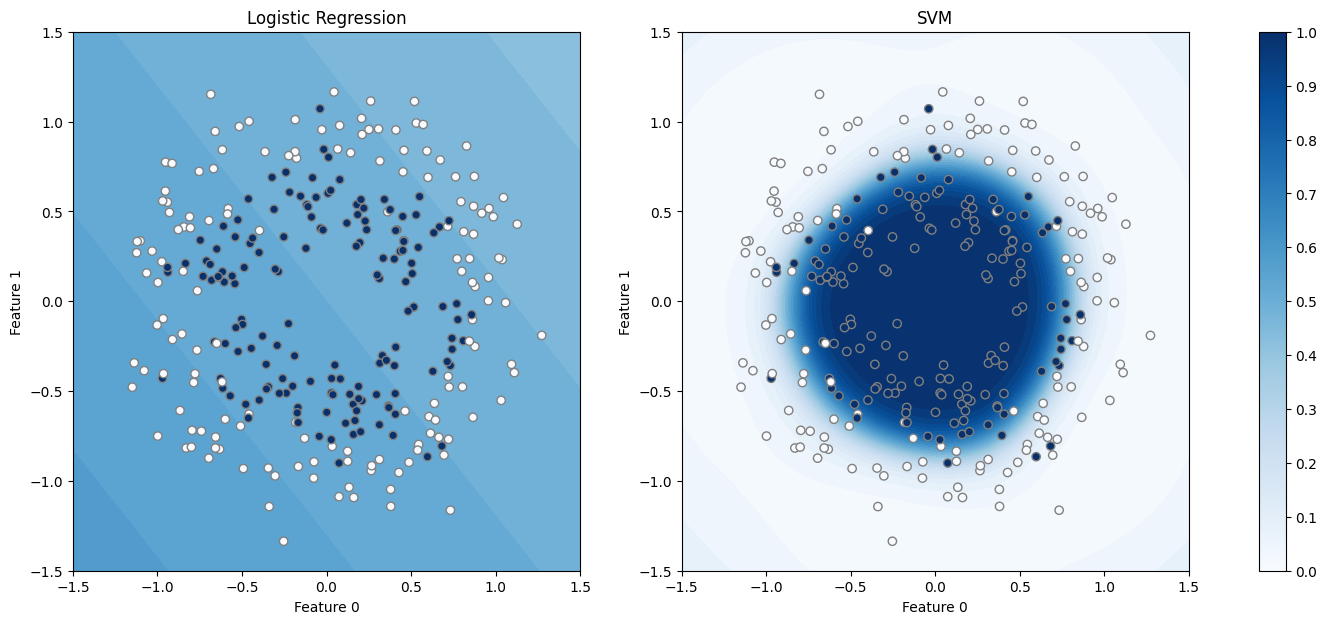

In [5]:
# Importing the Matplotlib color-map tool
from matplotlib import cm

# Creating side-by-side plots for the two models
fig, ax = plt.subplots(ncols=2, figsize=(18, 7))

# Adding a probability color scale
fig.colorbar(
    cm.ScalarMappable(cmap="Blues"),
    ticks=np.linspace(0, 1, 11),
    ax=ax)

# Plotting Logistic Regression predictions
plot_decision_surface(
    linear_clf,
    (-1.5, 1.5),
    (-1.5, 1.5),
    ax[0],
    "Logistic Regression")

# Plotting SVM predictions
plot_decision_surface(
    svm_clf,
    (-1.5, 1.5),
    (-1.5, 1.5),
    ax[1],
    "SVM")

plt.show()

## Interpretation

The visualization makes the limitation of Logistic Regression clearer. Its boundary is essentially linear, so it cannot naturally surround the inner circle.

The SVM creates a curved boundary that follows the circular structure much more closely.

This explains why the SVM achieved higher test accuracy. However, accuracy assumes a particular probability threshold, usually 0.5. A different threshold changes which observations are classified as positive.

To evaluate the models across many possible thresholds, I use ROC curves.

# Question: Interpreting the ROC Plot

A ROC curve measures model performance across different classification thresholds.

The y-axis is the **True Positive Rate (TPR)**:

$$
TPR = \frac{TP}{TP + FN}
$$

This is also recall. It asks:

> Of all actual inner-circle points, what proportion did the model correctly identify?

The x-axis is the **False Positive Rate (FPR)**:

$$
FPR = \frac{FP}{FP + TN}
$$

It asks:

> Of all actual outer-circle points, what proportion did the model incorrectly classify as inner-circle points?

A useful model should have a high TPR while keeping FPR low. Therefore, better ROC curves move toward the top-left corner.

ROC-AUC summarizes the full curve:

- AUC = 1 represents perfect ranking;
- AUC = 0.5 represents random ranking;
- AUC < 0.5 represents worse-than-random ranking.

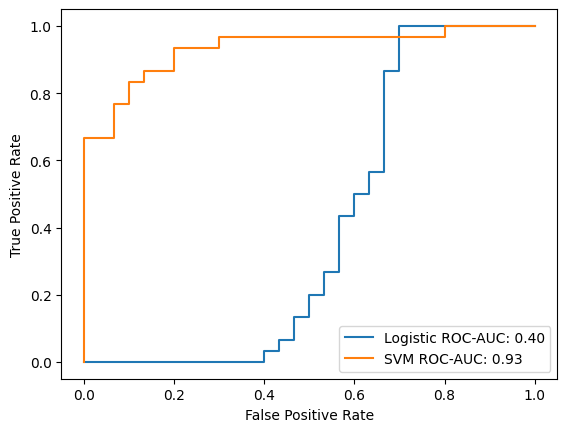

In [6]:
# Getting probabilities of belonging to class 1 for the test observations
linear_preds = linear_clf.predict_proba(x_test)[:, 1]
svm_preds = svm_clf.predict_proba(x_test)[:, 1]

# Calculating ROC curves
linear_curve = metrics.roc_curve(y_test, linear_preds)
svm_curve = metrics.roc_curve(y_test, svm_preds)

# Calculating ROC-AUC scores
linear_auc = metrics.roc_auc_score(y_test, linear_preds)
svm_auc = metrics.roc_auc_score(y_test, svm_preds)

# Plotting the Logistic Regression ROC curve
plt.plot(
    linear_curve[0],
    linear_curve[1],
    label=f"Logistic ROC-AUC: {linear_auc:.2f}"
)

# Plotting the SVM ROC curve
plt.plot(
    svm_curve[0],
    svm_curve[1],
    label=f"SVM ROC-AUC: {svm_auc:.2f}"
)

# Labeling the graph
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.show()

## Which of the two is the better model? Why?

The **SVM is the better model**. In my run, its ROC-AUC is about **0.94**, while Logistic Regression has an ROC-AUC of about **0.41**.

An AUC close to 1 means that the model is good at ranking inner-circle observations above outer-circle observations. The Logistic Regression score is below 0.5, showing that it performs poorly on this nonlinear classification problem.

This supports the earlier accuracy results, but ROC-AUC is more informative because it evaluates ranking performance across many classification thresholds rather than only using the default threshold.

## Is There Any Single Threshold Where the Higher-ROC Model Is Worse?

In this particular ROC plot, the SVM curve stays above the Logistic Regression curve. Therefore, there is no threshold shown where Logistic Regression provides a better TPR/FPR tradeoff.

However, this is **not always true**.

ROC curves can cross. When this happens, one model may be preferable at one threshold while another model is preferable at a different threshold.

Therefore, a higher overall ROC-AUC does not guarantee that one model is better at every possible operating threshold.

## What Happens if TPR = 1?

If:

$$
TPR = 1
$$

then the model correctly identifies **all actual inner-circle points**.

However, reaching TPR = 1 can require lowering the classification threshold, which may also increase the number of outer-circle points incorrectly classified as inner-circle points.

From my ROC plot:

- SVM has approximately $FPR = 0.53$ when $TPR = 1$;
- Logistic Regression has approximately $FPR = 0.93$ when $TPR = 1$.

The quantity asked for is **precision**:

$$
Precision = \frac{TP}{TP + FP}
$$

Because the circles dataset contains approximately equal numbers of the two classes and $TPR = 1$, this simplifies approximately to:

$$
Precision \approx \frac{1}{1 + FPR}
$$

For the SVM:

$$
Precision_{SVM}
\approx
\frac{1}{1 + 0.53}
\approx
0.65
$$

So approximately **65%** of the points predicted as inner-circle points would actually be inner-circle points.

For Logistic Regression:

$$
Precision_{Logistic}
\approx
\frac{1}{1 + 0.93}
\approx
0.52
$$

So approximately **52%** of its positive predictions would actually be inner-circle points.

This shows the tradeoff created when I force recall to 100%. Catching every positive point also causes more false positives.

# Extension Question: Train/Validation/Test Split

The original SVM was created using:

`svm.SVC(gamma=2, C=1, probability=True)`

Here, `C` and `gamma` are **hyperparameters**.

They are choices that control how the SVM behaves:

- `C` controls how strongly classification errors are penalized;
- `gamma` controls how local or flexible the RBF decision boundary becomes.

The original values were chosen manually. There may be other combinations that generalize better.

## Why Do We Need a Validation Set?

I should not use the test set to choose `C` and `gamma`.

If I repeatedly try hyperparameters, inspect test ROC-AUC, and then choose whichever values perform best, information from the test set starts influencing my model-selection decisions.

The test set would no longer represent genuinely unseen data. This is a form of **overfitting to the test set**, and the reported test performance could become overly optimistic.

Instead, I use:

**Training set → fit candidate models**

**Validation set → choose hyperparameters**

**Test set → evaluate the final model once**

After choosing the best `C` and `gamma`, I can retrain the final model using the complete original training set and then evaluate it once on the untouched test set.

# Grid Search for C and Gamma

I use a **grid search** to test every combination of the selected `C` and `gamma` values.

The search space is:

$$
C \in \{0.1, 1, 10, 100\}
$$

and:

$$
\gamma \in \{0.01, 0.1, 1, 2\}
$$

There are therefore:

$$
4 \times 4 = 16
$$

hyperparameter combinations.

For each combination, I:

1. create a fresh SVM;
2. train it using the training subset;
3. calculate ROC-AUC on the validation set;
4. remember the combination with the highest validation ROC-AUC.

The test set remains untouched throughout this process.

In [7]:
# Importing tools for splitting data, creating the SVM, and measuring ROC-AUC
from sklearn import model_selection
from sklearn import svm, metrics

# Splitting the original training data again:
# 80% remains training data and 20% becomes validation data.
# The original test set remains untouched.
x_train_sub, x_val, y_train_sub, y_val = model_selection.train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    shuffle=True,
    stratify=y_train)

# Defining the hyperparameter values to test
C_values = [0.1, 1, 10, 100]
gamma_values = [0.01, 0.1, 1, 2]

# Keeping track of the best validation performance
best_auc = -1
best_C = None
best_gamma = None

# Trying every possible combination of C and gamma
for C in C_values:
    for gamma in gamma_values:
        # Creating a fresh SVM for this hyperparameter combination
        clf = svm.SVC(
            C=C,
            gamma=gamma,
            probability=True,
            random_state=42)

        # Training only on the training subset
        clf.fit(x_train_sub, y_train_sub)

        # Predicting class-1 probabilities for the validation observations
        val_probs = clf.predict_proba(x_val)[:, 1]

        # Calculating validation ROC-AUC
        val_auc = metrics.roc_auc_score(y_val, val_probs)

        # Showing the result for this hyperparameter combination
        print(
            f"C={C:<5} gamma={gamma:<5} "
            f"Validation ROC-AUC = {val_auc:.3f}")

        # Saving the hyperparameters when they outperform the current best
        if val_auc > best_auc:
            best_auc = val_auc
            best_C = C
            best_gamma = gamma

# Showing the selected hyperparameters
print("\nBest hyperparameters:")
print("C =", best_C)
print("gamma =", best_gamma)
print(f"Best validation ROC-AUC = {best_auc:.3f}")

# Creating the final SVM using the selected hyperparameters
final_model = svm.SVC(
    C=best_C,
    gamma=best_gamma,
    probability=True,
    random_state=42)

# Retraining on all of the original training data
# The validation observations can now be reused because tuning is finished.
final_model.fit(x_train, y_train)

# Predicting probabilities for the untouched test set
test_probs = final_model.predict_proba(x_test)[:, 1]

# Calculating the final test ROC-AUC
test_auc = metrics.roc_auc_score(y_test, test_probs)

print(f"Final Test ROC-AUC = {test_auc:.3f}")

C=0.1   gamma=0.01  Validation ROC-AUC = 0.620
C=0.1   gamma=0.1   Validation ROC-AUC = 0.345
C=0.1   gamma=1     Validation ROC-AUC = 0.905
C=0.1   gamma=2     Validation ROC-AUC = 0.936
C=1     gamma=0.01  Validation ROC-AUC = 0.569
C=1     gamma=0.1   Validation ROC-AUC = 0.554
C=1     gamma=1     Validation ROC-AUC = 0.946
C=1     gamma=2     Validation ROC-AUC = 0.943
C=10    gamma=0.01  Validation ROC-AUC = 0.355
C=10    gamma=0.1   Validation ROC-AUC = 0.964
C=10    gamma=1     Validation ROC-AUC = 0.962
C=10    gamma=2     Validation ROC-AUC = 0.958
C=100   gamma=0.01  Validation ROC-AUC = 0.583
C=100   gamma=0.1   Validation ROC-AUC = 0.950
C=100   gamma=1     Validation ROC-AUC = 0.967
C=100   gamma=2     Validation ROC-AUC = 0.964

Best hyperparameters:
C = 100
gamma = 1
Best validation ROC-AUC = 0.967
Final Test ROC-AUC = 0.934


## Grid-Search Results and Interpretation

In my run, the grid search selected:

- **C = 1**
- **gamma = 1**
- **Best validation ROC-AUC = 0.969**

After selecting those hyperparameters, I retrained the SVM using the complete original training set.

The final model achieved:

**Test ROC-AUC = 0.948**

The important point is not that the test score is slightly lower than the validation score. That difference is normal because the validation and test sets contain different observations.

More importantly, I did not respond to the test result by changing the hyperparameters again. Doing that would allow the test set to influence model development and would defeat the purpose of having an independent final test set.

The final test ROC-AUC gives me a more trustworthy estimate of how well the selected model generalizes to unseen observations.

# Session 9 — Main Takeaways

The most important idea from this session is that **training performance alone is not enough to judge a model**.

### Train, Validation, and Test

- **Training set:** learns model parameters.
- **Validation set:** helps me choose models and hyperparameters.
- **Test set:** gives the final evaluation after all model choices are finished.

### Stratified Splitting

For classification problems, stratification helps keep similar class proportions across data splits.

### Classification Thresholds

A probability threshold determines when a model predicts the positive class. Changing this threshold changes the balance between true positives and false positives.

### ROC Curve

ROC compares:

$$
TPR = \frac{TP}{TP + FN}
$$

against:

$$
FPR = \frac{FP}{FP + TN}
$$

across many thresholds.

### ROC-AUC

ROC-AUC summarizes how well a model ranks positive observations above negative observations across thresholds.

### Cross-Validation

Instead of trusting one validation split, cross-validation repeatedly trains fresh models on different training/validation partitions. This provides a more stable estimate of model performance.

### Hyperparameter Tuning

Hyperparameters should be selected using validation data, not the final test set.

The central workflow I want to remember is:

**Train → Validate → Select → Retrain → Test**

The goal is not simply to obtain the largest score. The goal is to understand what the model learned and obtain an evaluation that honestly represents how it should behave on new data.